# Project : "Cell Phone Price Predication ML"

- Domain : Telecomunication 

# Business Case 

   "No-Charn telecom is an established Telecom in Europe with more than a decade in Bisiness. Due to new Players in the market, Telecom industry become very competitive and retaining customers becoming a challenge."

# Problem Statment

"In splite of No-Churn initiatives  

# Project Goal :

# ML Model Building Path :

1. Define Business Case, Problem & Project Goal
2. Imports Libraries
3. Data Load and Validation
4. Data Cleaning
5. Feature engineering 
6. Exploratory Data Analysis(EDA)
7. Outlier Ditection
8. Data Train & Test split 
9. Preprocessing Pipeline
10. Model Building 
11. Model Comparison & Cross Validation 
12. Feature Importance
13. Churn Risk Score and CHURN_FLAG
14. Save Model and Conclusion

# Import Libraries

In [11]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score, f1_score

# Data Load and Validation

In [12]:
# Load the dataset
df = pd.read_csv('datasets_11167_15520_train.csv')
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [13]:
# check dataset shape
df.shape

(2000, 21)

* Total Recoders : 2000
* Total Columns : 21

In [14]:
# Categorical columns
df.select_dtypes(include=['object']).columns

Index([], dtype='str')

In [15]:
# Numerical columns
df.select_dtypes(include=['int64', 'float64']).columns

Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='str')

In [16]:
# dataset information
df.describe(include='all')

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [17]:
# Check the structure and information of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

In [18]:
# Check the data types of each column
df.dtypes

battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
price_range        int64
dtype: object

In [19]:
# Check Duplicate
df.duplicated().sum()

np.int64(0)

In [20]:
# Check Missing Values
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

# Data Cleaning

In [22]:
print("No Null values in the dataset:",df.isnull().sum().sum())

No Null values in the dataset: 0


# Feature engineering

In [23]:
# Combine related specifications into more informative features

# Total screen resolution (pixel area)
df['pixel_resolution'] = df['px_height'] * df['px_width']

# Approximate screen area and camera resolution
df['screen_area'] = df['sc_h'] * df['sc_w']
df['camera_resolution'] = df['pc'] + df['fc']

# Hardware efficiency and connectivity summaries
df['battery_per_weight'] = df['battery_power'] / df['mobile_wt'].replace(0, np.nan)
df['ram_per_core'] = df['ram'] / df['n_cores'].replace(0, np.nan)
df['connectivity_score'] = df[['blue', 'dual_sim', 'four_g', 'three_g', 'wifi']].sum(axis=1)

# Screen aspect ratio, using zero for records with no reported screen height
df['screen_aspect_ratio'] = np.where(
    df['px_height'].eq(0),
    0.0,
    df['px_width'] / df['px_height']
)

engineered_features = [
    'pixel_resolution', 'screen_area', 'camera_resolution',
    'battery_per_weight', 'ram_per_core', 'connectivity_score',
    'screen_aspect_ratio'
]

# Guard against infinite values created by a zero denominator
df[engineered_features] = df[engineered_features].replace([np.inf, -np.inf], np.nan)
print('Engineered features:', len(engineered_features))
print(df[engineered_features].head())

Engineered features: 7
   pixel_resolution  screen_area  camera_resolution  battery_per_weight  \
0             15120           63                  3            4.478723   
1           1799140           51                  6            7.507353   
2           2167308           22                  8            3.882759   
3           2171776          128                  9            4.694656   
4           1464096           16                 27           12.914894   

   ram_per_core  connectivity_score  screen_aspect_ratio  
0        1274.5                   1            37.800000  
1         877.0                   4             2.196685  
2         520.6                   4             1.358670  
3         461.5                   2             1.468750  
4         705.5                   3             1.003311  


## Explanation :

Feature engineering means combining existing data to create useful new information for the model. This code adds these features:

- **Pixel resolution:** Multiplies pixel height by pixel width to estimate the total number of pixels.
- **Screen area:** Multiplies screen height by screen width.
- **Camera resolution:** Adds the front-camera and primary-camera values.
- **Battery per weight:** Divides battery power by phone weight, giving a simple battery-to-weight measure.
- **RAM per core:** Divides RAM by the number of processor cores.
- **Connectivity score:** Counts how many of Bluetooth, dual SIM, 3G, 4G, and Wi-Fi are available.
- **Screen aspect ratio:** Divides pixel width by pixel height. If pixel height is zero, the code uses zero instead to avoid division by zero.

The `engineered_features` list keeps the names of all seven new columns together. The final line replaces any infinite values with missing values, then the code prints the number of new features and shows their first few values. These features are made from phone specifications, not the `price_range` target.


# Exploratory Data Analysis(EDA) :

Phone count by price range:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


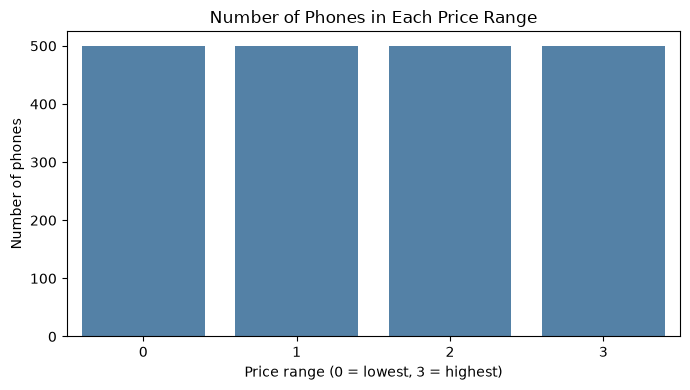

In [28]:
# Count phones in each price range
price_order = sorted(df['price_range'].unique())

print("Phone count by price range:")
print(df['price_range'].value_counts().sort_index())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='price_range', order=price_order, color='steelblue')
plt.title('Number of Phones in Each Price Range')
plt.xlabel('Price range (0 = lowest, 3 = highest)')
plt.ylabel('Number of phones')
plt.tight_layout()
plt.show()

### Price Range Distribution

This code checks how many phones belong to each price range and displays the counts in a bar chart.

- `price_order` puts the price-range labels in order: 0, 1, 2, and 3.
- `value_counts()` counts the phones in each range. `sort_index()` displays the counts in price-range order.
- The bar chart shows the number of phones in each range. The labels and title make the chart easier to understand.

**Observation:** The dataset contains 500 phones in each price range, so the four classes are evenly represented.

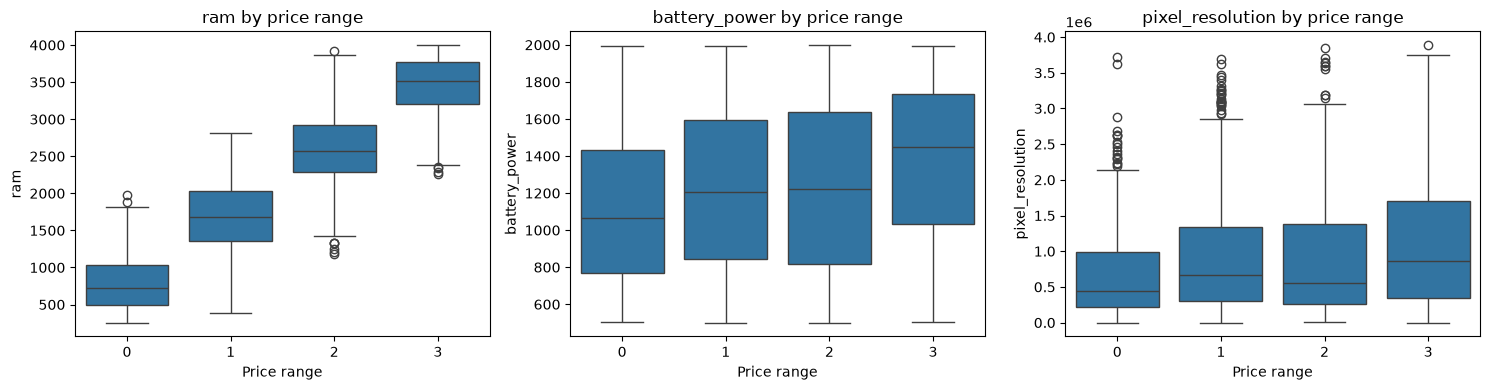

In [26]:
# Compare selected phone specifications across price ranges
features_to_compare = ['ram', 'battery_power', 'pixel_resolution']

fig, axes = plt.subplots(1, len(features_to_compare), figsize=(15, 4))

for ax, feature in zip(axes, features_to_compare):
    sns.boxplot(data=df, x='price_range', y=feature, order=price_order, ax=ax)
    ax.set_title(f'{feature} by price range')
    ax.set_xlabel('Price range')

plt.tight_layout()
plt.show()

### Comparing Phone Specifications by Price Range

These boxplots compare RAM, battery power, and pixel resolution across the four price ranges (0 = lowest, 3 = highest).

- The line inside each box shows the **median** value.
- The box shows the middle half of the data.
- The whiskers show the wider spread of typical values. Circles mark possible outliers.

**Observations:**
- RAM generally increases from lower to higher price ranges, making it a strong indicator of price range in this dataset.
- Battery power tends to be higher in price range 3, but the values overlap across groups.
- Pixel resolution varies widely within each group, and the groups overlap considerably.

These charts show patterns in the data; they do not prove that a specification causes a phone to have a particular price range.

battery_power              ram         mobile_wt         \
                     mean  median     mean  median      mean median   
price_range                                                           
0                 1116.90  1066.0   785.31   719.5    140.55  142.0   
1                 1228.87  1206.0  1679.49  1686.5    140.51  141.0   
2                 1228.32  1219.5  2582.82  2577.0    143.61  145.0   
3                 1379.98  1449.5  3449.23  3509.5    136.32  134.0   

            pixel_resolution           screen_area         
                        mean    median        mean median  
price_range                                                
0                  678837.80  448852.0       78.55   56.0  
1                  930234.07  661429.0       77.04   53.0  
2                  880749.47  560907.0       77.63   51.0  
3                 1131218.88  860881.0       87.80   57.0

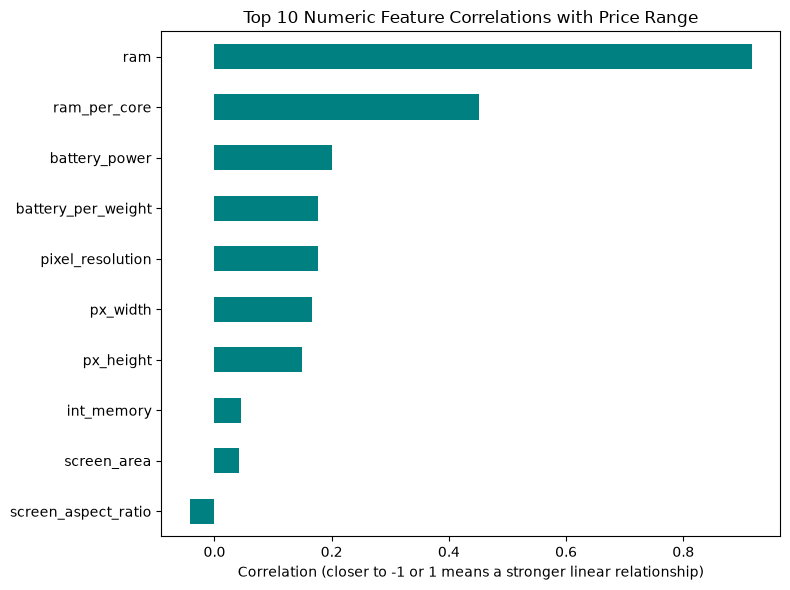

In [27]:
# Compare average and median specifications by price range
summary_features = [
    'battery_power',
    'ram',
    'mobile_wt',
    'pixel_resolution',
    'screen_area'
]

display(
    df.groupby('price_range')[summary_features]
      .agg(['mean', 'median'])
      .round(2)
)


# Find numeric features most correlated with price range
numeric_correlations = (
    df.select_dtypes(include=np.number)
      .corr()['price_range']
      .drop('price_range')
)

top_correlations = numeric_correlations.reindex(
    numeric_correlations.abs()
                      .sort_values(ascending=False)
                      .head(10)
                      .index
).sort_values()

plt.figure(figsize=(8, 6))
top_correlations.plot(kind='barh', color='teal')
plt.title('Top 10 Numeric Feature Correlations with Price Range')
plt.xlabel('Correlation (closer to -1 or 1 means a stronger linear relationship)')
plt.tight_layout()
plt.show()

## Additional EDA: Feature Patterns and Relationships

The earlier EDA checks price-range counts, selected boxplots, summary statistics, and numeric correlations. The following views explore more feature distributions and how specifications vary together. Run these cells after feature engineering so the derived columns are available.

### 1. Distribution of key specifications within each price range

Faceted histograms show the shape and spread of selected numeric features for each class. This helps reveal overlap, skew, and whether class patterns are consistent across the range.

In [ ]:
# Compare distributions separately for each price class
features_to_distribute = ['ram', 'battery_power', 'mobile_wt', 'clock_speed']

fig, axes = plt.subplots(len(features_to_distribute), 1, figsize=(10, 3.2 * len(features_to_distribute)))
for ax, feature in zip(axes, features_to_distribute):
    sns.histplot(
        data=df, x=feature, hue='price_range', hue_order=price_order,
        bins=25, stat='density', common_norm=False, element='step',
        fill=False, ax=ax
    )
    ax.set_title(f'{feature} distribution by price range')
    ax.set_ylabel('Density')
plt.tight_layout()
plt.show()


### 2. Standardized feature profile by price range

This heatmap compares class means for selected specifications after standardizing each feature across the full dataset. Positive values mean that class is above the overall feature mean; negative values mean it is below. Standardization makes differently scaled measurements easier to compare.

In [ ]:
# Compare class averages on a common scale (z-scores)
profile_features = [
    'battery_power', 'clock_speed', 'int_memory', 'mobile_wt',
    'ram', 'talk_time', 'pixel_resolution', 'screen_area'
]
class_means = df.groupby('price_range')[profile_features].mean()
feature_std = df[profile_features].std(ddof=0).replace(0, np.nan)
class_profile_z = (class_means - df[profile_features].mean()) / feature_std

plt.figure(figsize=(11, 4.5))
sns.heatmap(class_profile_z, annot=True, fmt='.2f', cmap='vlag', center=0,
            linewidths=.5, cbar_kws={'label': 'Standardized class mean (z-score)'})
plt.title('Phone Specification Profile by Price Range')
plt.xlabel('Feature')
plt.ylabel('Price range (0 = lowest, 3 = highest)')
plt.tight_layout()
plt.show()


### 3. Availability of binary features by price range

For 0/1 columns, the average is the proportion of phones with that feature. This chart displays those percentages for connectivity and usability features across price classes.

In [ ]:
# For binary features, class mean equals the proportion of phones with value 1
binary_features = [
    'blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi'
]
availability = df.groupby('price_range')[binary_features].mean().T * 100

ax = availability.plot(kind='bar', figsize=(11, 5), width=.8)
ax.set_title('Feature Availability by Price Range')
ax.set_xlabel('Binary phone feature')
ax.set_ylabel('Phones with feature (%)')
ax.legend(title='Price range', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 4. RAM and battery relationship

The scatter plot shows two core specifications together, colored by target class. It can reveal class separation and overlap that one-feature-at-a-time charts may miss. Transparency helps with overlapping points.

In [ ]:
# View the relationship between two important specifications
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x='battery_power', y='ram', hue='price_range',
    hue_order=price_order, palette='viridis', alpha=.55, s=35
)
plt.title('RAM vs Battery Power by Price Range')
plt.xlabel('Battery power')
plt.ylabel('RAM')
plt.legend(title='Price range')
plt.tight_layout()
plt.show()


**How to interpret these plots:** Use them to describe patterns and class overlap in this dataset. They are exploratory summaries, not evidence that a feature causes a phone to cost more. Since `price_range` is an ordered class label (0?3), its numeric code should not be treated as an exact selling price.